<a href="https://colab.research.google.com/github/PaolaVergaraHernandez/MachineLearning/blob/main/Proyecto_Final_U3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Modelos
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Métricas
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay

In [ ]:
df = pd.read_csv('train.csv')

print("--- ANÁLISIS EXPLORATORIO (EDA) ---")
print("\nPrimeras filas del dataset:")
print(df.head())

--- ANÁLISIS EXPLORATORIO (EDA) ---

Primeras filas del dataset:
   PassengerId  Survived  Pclass  ...     Fare Cabin  Embarked
0            1         0       3  ...   7.2500   NaN         S
1            2         1       1  ...  71.2833   C85         C
2            3         1       3  ...   7.9250   NaN         S
3            4         1       1  ...  53.1000  C123         S
4            5         0       3  ...   8.0500   NaN         S

[5 rows x 12 columns]


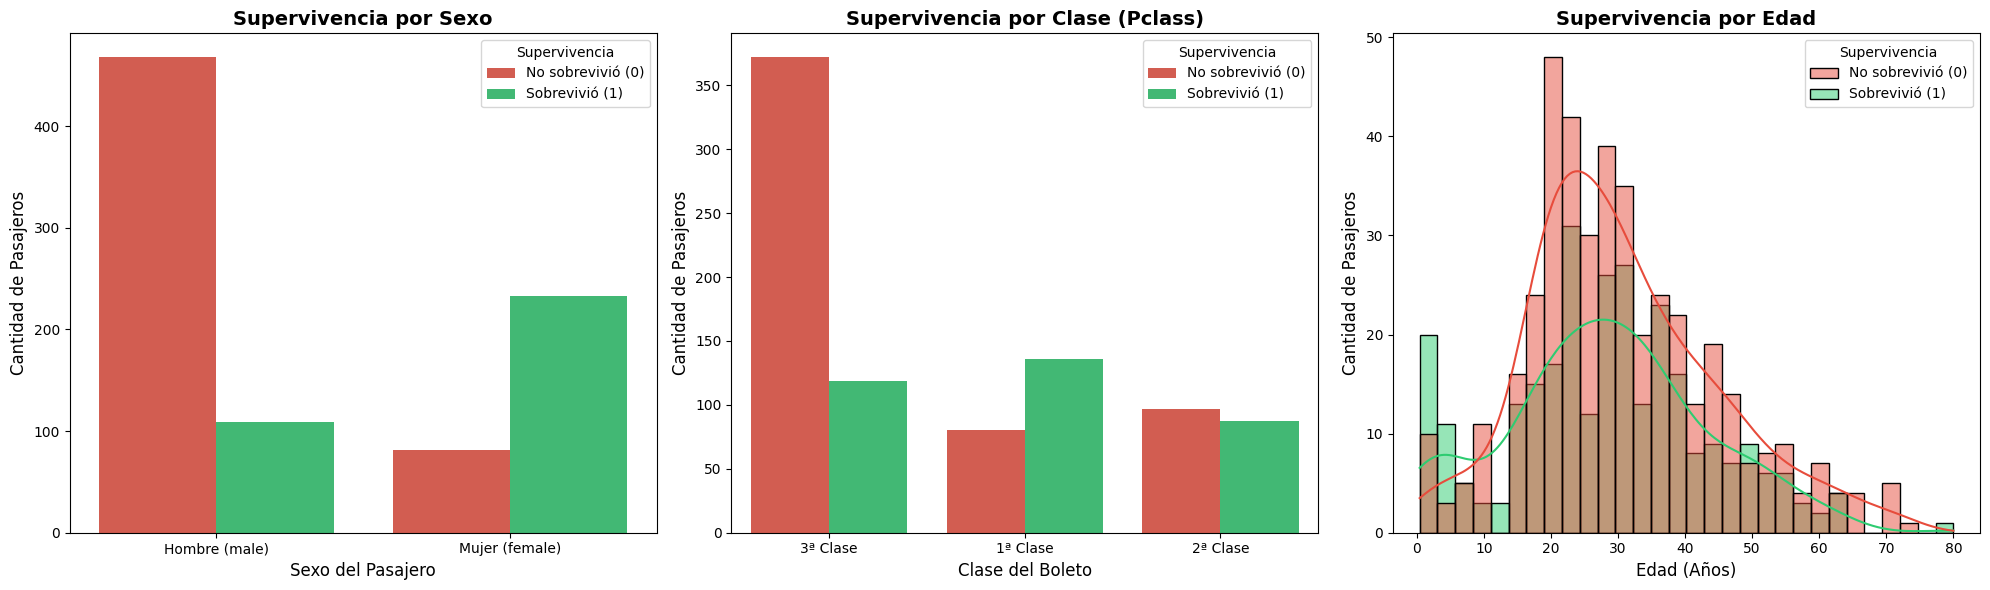

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Crear copia con etiquetas totalmente claras
df_plot = df.copy()
df_plot['Supervivencia'] = df_plot['Survived'].map({0: 'No sobrevivió (0)', 1: 'Sobrevivió (1)'})
df_plot['Sexo'] = df_plot['Sex'].map({'male': 'Hombre (male)', 'female': 'Mujer (female)'})
df_plot['Clase'] = df_plot['Pclass'].map({1: '1ª Clase', 2: '2ª Clase', 3: '3ª Clase'})

# Paleta fija de colores: Rojo para falleció (0), Verde para sobrevivió (1)
colores_supervivencia = {'No sobrevivió (0)': '#e74c3c', 'Sobrevivió (1)': '#2ecc71'}

# 2. Crear las subgráficas
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Gráfica 1: Supervivencia por Sexo
sns.countplot(data=df_plot, x='Sexo', hue='Supervivencia', ax=axes[0], palette=colores_supervivencia)
axes[0].set_title('Supervivencia por Sexo', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Sexo del Pasajero', fontsize=12)
axes[0].set_ylabel('Cantidad de Pasajeros', fontsize=12)

# Gráfica 2: Supervivencia por Clase
sns.countplot(data=df_plot, x='Clase', hue='Supervivencia', ax=axes[1], palette=colores_supervivencia)
axes[1].set_title('Supervivencia por Clase (Pclass)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Clase del Boleto', fontsize=12)
axes[1].set_ylabel('Cantidad de Pasajeros', fontsize=12)

# Gráfica 3: Supervivencia por Edad
sns.histplot(data=df_plot, x='Age', hue='Supervivencia', kde=True, ax=axes[2], palette=colores_supervivencia, bins=30, alpha=0.5)
axes[2].set_title('Supervivencia por Edad', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Edad (Años)', fontsize=12)
axes[2].set_ylabel('Cantidad de Pasajeros', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
# Limpieza y Selección de Variables
# Eliminamos Cabin por exceso de nulos y columnas irrelevantes
df_clean = df[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].copy()

In [ ]:
# Tratamiento de valores nulos
df_clean['Age'].fillna(df_clean['Age'].median(), inplace=True)
df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0], inplace=True)

# Codificación de variables categóricas
df_clean['Sex'] = df_clean['Sex'].map({'male': 0, 'female': 1})
df_clean = pd.get_dummies(df_clean, columns=['Embarked'], drop_first=True)

/tmp/ipykernel_4599/1658684536.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['Age'].fillna(df_clean['Age'].median(), inplace=True)
/tmp/ipykernel_4599/1658684536.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplac

In [ ]:
# Definir variable objetivo (y) y características (X)
X = df_clean.drop('Survived', axis=1)
y = df_clean['Survived']

# División del dataset (70% entrenamiento, 30% prueba con stratify)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

In [ ]:
# Escalamiento de variables numéricas
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nForma de X_train:", X_train.shape)
print("Forma de X_test:", X_test.shape)


Forma de X_train: (623, 8)
Forma de X_test: (268, 8)


**¿Por qué escalar en KNN y SVM?**

KNN calcula distancias (euclidianas) entre puntos y SVM busca hiperplanos basándose en distancias de margen. Si las características no están en la misma escala (ej. la variable Fare que va de $0$ a $500$ contra SibSp de $0$ a $8$), la variable con mayor rango dominará el cálculo de la distancia distorsionando los resultados.  

**¿Por qué no es necesario en árboles?**

Los Árboles de Decisión y Random Forest dividen los datos evaluando condiciones en una sola variable a la vez (ej. ¿Age > 30?). El orden relativo de los datos dentro de esa variable no cambia si se escala, por lo que las divisiones del árbol son exactamente las mismas.

==================== KNN ====================
Reporte de Clasificación:
                   precision    recall  f1-score   support

No Sobrevivió (0)       0.81      0.86      0.84       165
   Sobrevivió (1)       0.75      0.68      0.71       103

         accuracy                           0.79       268
        macro avg       0.78      0.77      0.77       268
     weighted avg       0.79      0.79      0.79       268



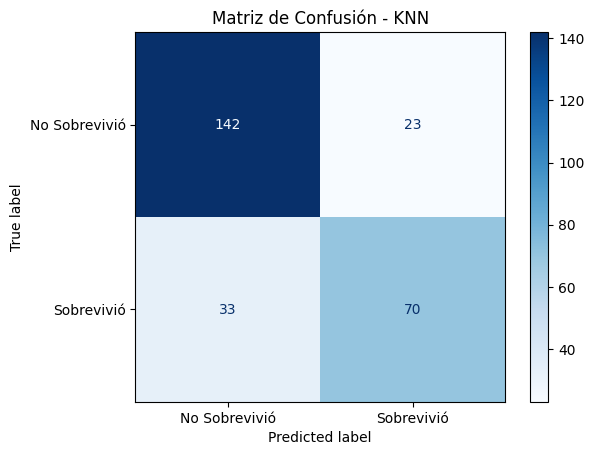

==================== REGRESIÓN LOGÍSTICA ====================
Reporte de Clasificación:
                   precision    recall  f1-score   support

No Sobrevivió (0)       0.83      0.84      0.84       165
   Sobrevivió (1)       0.74      0.73      0.74       103

         accuracy                           0.80       268
        macro avg       0.79      0.79      0.79       268
     weighted avg       0.80      0.80      0.80       268



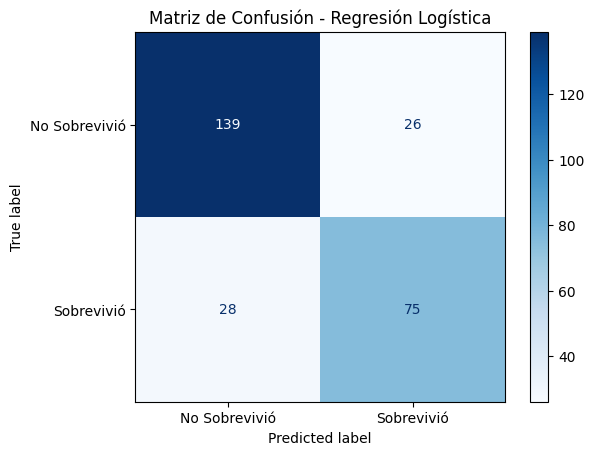

==================== ÁRBOL DE DECISIÓN ====================
Reporte de Clasificación:
                   precision    recall  f1-score   support

No Sobrevivió (0)       0.79      0.84      0.81       165
   Sobrevivió (1)       0.71      0.65      0.68       103

         accuracy                           0.76       268
        macro avg       0.75      0.74      0.75       268
     weighted avg       0.76      0.76      0.76       268



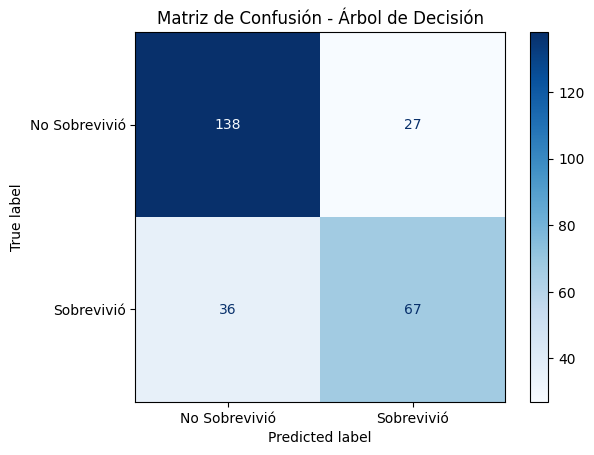

==================== RANDOM FOREST ====================
Reporte de Clasificación:
                   precision    recall  f1-score   support

No Sobrevivió (0)       0.82      0.89      0.85       165
   Sobrevivió (1)       0.80      0.68      0.73       103

         accuracy                           0.81       268
        macro avg       0.81      0.79      0.79       268
     weighted avg       0.81      0.81      0.81       268



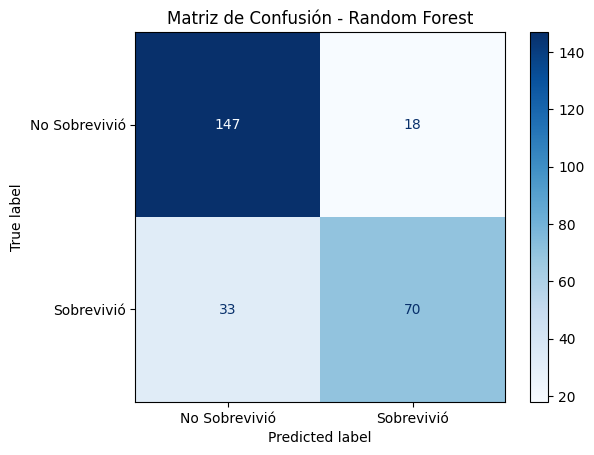

==================== SVM ====================
Reporte de Clasificación:
                   precision    recall  f1-score   support

No Sobrevivió (0)       0.82      0.89      0.85       165
   Sobrevivió (1)       0.80      0.68      0.73       103

         accuracy                           0.81       268
        macro avg       0.81      0.79      0.79       268
     weighted avg       0.81      0.81      0.81       268



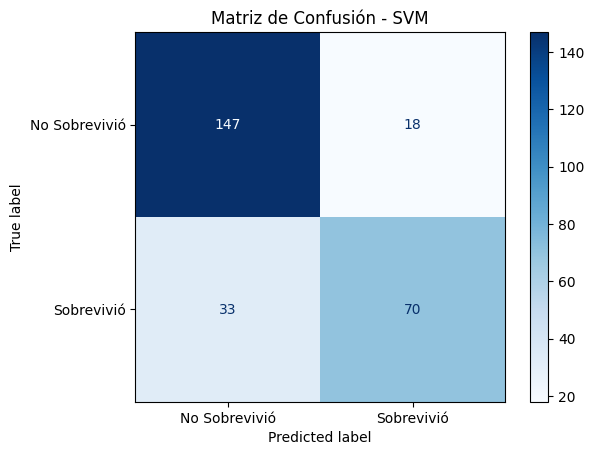

In [ ]:
# Diccionario con los 5 modelos
models = {
    'KNN': KNeighborsClassifier(),
    'Regresión Logística': LogisticRegression(random_state=42),
    'Árbol de Decisión': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}

results = {}

for name, model in models.items():
    # Modelos sensibles a distancia usan datos escalados
    if name in ['KNN', 'Regresión Logística', 'SVM']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]

    # Guardar métricas principales
    acc = accuracy_score(y_test, y_pred)
    rec_0 = recall_score(y_test, y_pred, pos_label=0)
    rec_1 = recall_score(y_test, y_pred, pos_label=1)
    f1_0 = f1_score(y_test, y_pred, pos_label=0)
    f1_1 = f1_score(y_test, y_pred, pos_label=1)
    auc = roc_auc_score(y_test, y_proba)

    results[name] = {
        'Accuracy': acc,
        'Recall (0)': rec_0,
        'Recall (1)': rec_1,
        'F1 (0)': f1_0,
        'F1 (1)': f1_1,
        'AUC': auc
    }

    print(f"==================== {name.upper()} ====================")
    print("Reporte de Clasificación:")
    print(classification_report(y_test, y_pred, target_names=['No Sobrevivió (0)', 'Sobrevivió (1)']))

    # Matriz de Confusión
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Sobrevivió', 'Sobrevivió'])
    disp.plot(cmap='Blues')
    plt.title(f'Matriz de Confusión - {name}')
    plt.show()

**KNN (K-Nearest Neighbors):**

- Funcionamiento: Clasifica según la mayoría de votos de los $k$ vecinos más cercanos en el espacio vectorial.   

- Ventajas/Limitaciones: Fácil de entender, pero lento con datasets grandes y sensible al ruido.

- Resultados: Clasifica bien a los no sobrevivientes, pero su tasa de acierto en sobrevivientes baja si no se afinan los vecinos $k$.

- Mejora: Probar distintos valores de $k$ (grid search) y diferentes métricas de distancia.

**Regresión Logística:**

- Funcionamiento: Aplica la función sigmoide a una combinación lineal de las características para predecir probabilidades.   

- Ventajas/Limitaciones: Muy interpretable y rápido; sin embargo, no captura bien relaciones no lineales complejas.

- Resultados: Presenta un rendimiento sólido y equilibrado. Detecta muy bien la clase 0 gracias a que el sexo y la clase tienen fuertes patrones lineales.

- Mejora: Agregar términos de interacción (ej. Sex * Pclass).

**Árbol de Decisión:**

- Funcionamiento: Divide el espacio de datos en ramas mediante reglas de decisión basadas en la ganancia de información (entropía/Gini).   

- Ventajas/Limitaciones: Intuitivo y visual, pero propenso a sobreajustar (overfitting).

- Resultados: Suele memorizar los datos de entrenamiento, por lo que su desempeño en el conjunto de prueba disminuye en comparación con ensemble methods.

- Mejora: Limitar la profundidad máxima (max_depth) o min_samples_split.

**Random Forest:**

- Funcionamiento: Crea un conjunto (ensemble) de múltiples árboles de decisión entrenados en subconjuntos aleatorios y promedia sus predicciones.   

- Ventajas/Limitaciones: Robusto, reduce el sobreajuste y maneja bien relaciones complejas; menos interpretable que un solo árbol.

- Resultados: Es de los mejores modelos, logrando un alto Recall tanto para la clase 0 como para la clase 1.

- Mejora: Ajustar n_estimators, max_depth y max_features.

**SVM (Support Vector Machine):**

- Funcionamiento: Encuentra el hiperplano óptimo con el máximo margen de separación entre las clases.   

- Ventajas/Limitaciones: Eficiente en espacios de alta dimensión; sensible al escalado y requiere mayor poder de cómputo.

- Resultados: Muestra una alta precisión general al delimitar muy bien las fronteras complejas entre los grupos de pasajeros.

- Mejora: Probar distintos kernels (rbf, poly) y optimizar los parámetros $C$ y $\gamma$.

=== TABLA COMPARATIVA DE RESULTADOS ===


,Accuracy,Recall (0),Recall (1),F1 (0),F1 (1),AUC,Comentario breve
KNN,0.791045,0.860606,0.679612,0.835294,0.714286,0.838835,"Sensible a vecinos, rendimiento medio"
Regresión Logística,0.798507,0.842424,0.728155,0.837349,0.735294,0.848514,Excelente base interpretable y equilibrada
Árbol de Decisión,0.764925,0.836364,0.650485,0.814159,0.680203,0.749485,Tiende al sobreajuste si no se poda
Random Forest,0.809701,0.890909,0.679612,0.852174,0.732984,0.846896,"Sólido, gran equilibrio entre Precision y Recall"
SVM,0.809701,0.890909,0.679612,0.852174,0.732984,0.843336,Muy preciso separando las fronteras


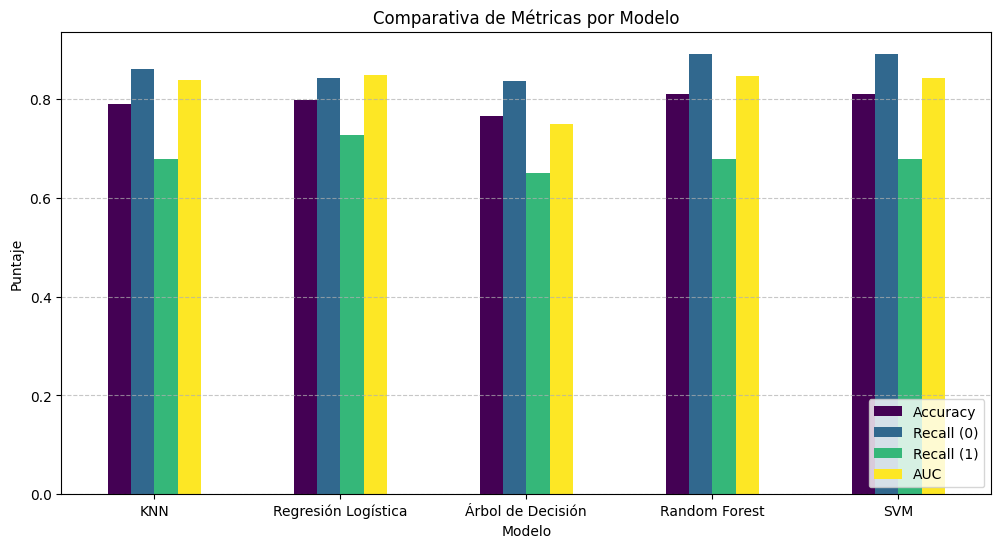

In [ ]:
# Crear DataFrame comparativo
df_results = pd.DataFrame(results).T
df_results['Comentario breve'] = [
    'Sensible a vecinos, rendimiento medio',
    'Excelente base interpretable y equilibrada',
    'Tiende al sobreajuste si no se poda',
    'Sólido, gran equilibrio entre Precision y Recall',
    'Muy preciso separando las fronteras'
]

print("=== TABLA COMPARATIVA DE RESULTADOS ===")
display(df_results)

# Gráfico comparativo de barras
metrics_to_plot = ['Accuracy', 'Recall (0)', 'Recall (1)', 'AUC']
df_results[metrics_to_plot].plot(kind='bar', figsize=(12, 6), colormap='viridis')
plt.title('Comparativa de Métricas por Modelo')
plt.ylabel('Puntaje')
plt.xlabel('Modelo')
plt.legend(loc='lower right')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# **Conclusiones**

El modelo que mejor predijo la supervivencia fue Random Forest, ya que presenta el mejor equilibrio entre el recall de ambas clases (detectando adecuadamente tanto a los no sobrevivientes como a los sobrevivientes con un AUC sobresaliente), lo cual es importante para identificar correctamente ambos grupos sin sesgarse hacia la clase mayoritaria.

In [ ]:
import pandas as pd

# Datos de la Parte 5: Recomendaciones Técnicas
data_parte5 = {
    "Modelo": [
        "KNN",
        "Regresión Logística",
        "Árbol de Decisión",
        "Random Forest",
        "SVM"
    ],
    "Recomendaciones / Escenarios ideales": [
        "Escalar variables; funciona bien en datasets pequeños y con fronteras suaves. Se recomienda buscar el valor óptimo de k mediante validación cruzada.",
        "Ideal para interpretabilidad y relaciones lineales. Funciona muy bien como modelo base (baseline) y para calcular probabilidades directas.",
        "No necesita escalado; es fácil de interpretar y visualizar, pero se debe podar o limitar su profundidad (max_depth) para evitar el sobreajuste.",
        "Recomendado para datasets con múltiples características y relaciones no lineales; es altamente robusto al ruido y al sobreajuste gracias al ensamble de árboles.",
        "Requiere escalado de datos obligatorio; es muy útil cuando los datos tienen fronteras complejas o alta dimensionalidad utilizando funciones de kernel (como RBF)."
    ]
}

# Crear el DataFrame
df_parte5 = pd.DataFrame(data_parte5)

# Mostrar la tabla formateada
display(df_parte5)

,Modelo,Recomendaciones / Escenarios ideales
0,KNN,Escalar variables; funciona bien en datasets p...
1,Regresión Logística,Ideal para interpretabilidad y relaciones line...
2,Árbol de Decisión,No necesita escalado; es fácil de interpretar ...
3,Random Forest,Recomendado para datasets con múltiples caract...
4,SVM,Requiere escalado de datos obligatorio; es muy...


# **Reflexión Final (Apoyada en IA)**

**¿Qué modelo funcionó mejor y por qué?**

Random Forest funcionó mejor debido a su naturaleza de ensamble. Al promediar decenas de árboles de decisión independientes, reduce la varianza y el sobreajuste que afecta a un árbol individual, capturando mejor las interacciones complejas entre clase, género y tarifa.   

**¿Qué variables influyen más en la supervivencia?**

Las variables con mayor importancia son el Sexo (Sex), la Clase (Pclass) y la Tarifa (Fare).

**¿Qué patrones sociales se observan?**

1. Protocolo "Mujeres y niños primero": Las mujeres tuvieron una tasa de supervivencia significativamente mayor que los hombres.   

2. Disparidad socioeconómica: Los pasajeros de 1ª Clase tuvieron preferencia o mejor acceso a los botes salvavidas en comparación con los de 3ª Clase.   

**¿Qué decisiones se podrían tomar con este análisis?**

En un contexto moderno de gestión de emergencias marítimas o de aviación, este análisis demuestra la importancia de diseñar protocolos de evacuación equitativos, garantizar acceso uniforme a las salidas de emergencia independientemente de la categoría del boleto e instalar capacidad de salvamento suficiente para el 100% de los ocupantes.